# [실습] 회귀 — 숫자를 예측하고 오차로 말하기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 2 실습. 이 집은 얼마에 팔릴까?

**필수 머신러닝 · Chapter 2**

| Part | 주제 |
| --- | --- |
| Part 1 | 데이터와 친해지기 |
| Part 2 | 베이스라인 고르기 |
| Part 3 | 현행 방법 만들기: 사람의 시세 규칙 |
| Part 4 | 모델 만들기와 실험 기록 |
| Part 5 | 오차 들여다보기와 보고 |

## 분석 의뢰서

> **의뢰 부서**: 부동산 플랫폼 기획팀
> **목적**: 매물을 등록할 때 "이 집은 대략 얼마" 하는 적정 시세를 자동으로 제시하고 싶다.
> **제약**: 시세가 실제 거래가와 너무 다르면 판매자와 구매자 모두 플랫폼을 믿지 않게 된다.
> **질문**: 집의 정보로 거래가를 얼마나 정확히 예측할 수 있을까?

## 이 실습의 질문

> **기획팀에 "이 모델의 시세는 평균적으로 ±얼마"라고 말한다면, 어떤 지표로 얼마라고 말할 것인가? 그리고 그 숫자를 믿어도 되는 집과 믿으면 안 되는 집은 어떻게 다른가?**

Chapter 1과 같은 순서로 진행합니다. 여러분이 먼저 중개사처럼 **사람의 시세 규칙**을 만들고, 그 시세 규칙과 모델을 **같은 평가용 데이터**에서 비교합니다. 마지막에는 기획팀에 보낼 보고 메모를 씁니다.

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |

## 준비

Kaggle의 House Prices 대회 데이터인 `train.csv`(Ames Housing, 1,460채)를 이 노트북과 같은 폴더에 두세요.

In [1]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 데이터와 친해지기

강의에서는 피처 다섯 개만 썼습니다. 여기서는 데이터에 실제로 어떤 문제가 들어 있는지 직접 확인하고, 그 문제를 어떻게 다룰지 스스로 정합니다.

## 1-1. 데이터 불러오기

**[직접 작성]** `train.csv`를 불러와 `df`에 저장하고, 행과 열의 수와 처음 5행을 확인하세요.

<details><summary>힌트</summary>

`pd.read_csv("파일 이름")`, `df.shape`, `df.head()`를 쓰세요. 열이 많아서 `df.head()`는 일부만 보입니다.
</details>

In [4]:
import shutil
from datetime import datetime
from pathlib import Path

import kagglehub

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

csv_file = "house-prices-advanced-regression-techniques/train.csv"
df = pd.read_csv(csv_file)
print("행과 열:",df.shape)
df.head()

행과 열: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1-2. 거래가 살펴보기

**[직접 작성]** 거래가(`SalePrice`)의 평균, 중앙값, 최솟값, 최댓값을 확인하세요.

<details><summary>힌트</summary>

`df["SalePrice"].describe()`가 한 번에 보여 줍니다. 중앙값은 `50%` 줄입니다.
</details>

In [5]:
df["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

**[제공]** 거래가의 분포를 그려 봅니다.

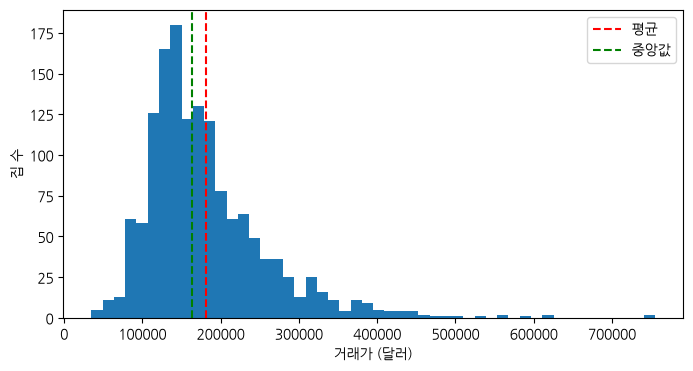

In [6]:
# [제공] 거래가 분포
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["SalePrice"], bins=50)
ax.axvline(df["SalePrice"].mean(), color="red", linestyle="--", label="평균")
ax.axvline(df["SalePrice"].median(), color="green", linestyle="--", label="중앙값")
ax.set_xlabel("거래가 (달러)")
ax.set_ylabel("집 수")
ax.legend()
plt.show()

> **[판단]** 평균과 중앙값 중 어느 쪽이 더 큰가요? 그 이유는 무엇이고, 이 특징이 "모델이 크게 틀리는 집"에 어떤 영향을 줄 것 같나요?
>
> 나의 답: 평균이 중앙값보다 더 크다. 오른쪽으로 꼬리가 길기 때문이다. (오른쪽 왜도)

## 1-3. 빈 값 찾기

**[직접 작성]** 빈 값이 있는 열을 빈 값이 많은 순서로 10개 확인하세요.

<details><summary>힌트</summary>

`df.isna().sum()`은 열마다 빈 값의 수를 셉니다. `.sort_values(ascending=False)`로 정렬하고 `.head(10)`으로 위쪽만 보세요.
</details>

In [12]:
df.isna().sum().sort_values(ascending=False).head(10)


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
dtype: int64

> **[판단]** 수영장 품질(`PoolQC`)이 1,453채나 비어 있습니다. 정말로 정보가 없는 걸까요, 아니면 다른 뜻일까요? 데이터 설명서에서는 이런 열의 빈 값(NA)을 "해당 시설 없음"으로 정의합니다. 이 점을 알면 빈 값을 어떻게 다루겠습니까?
>
> 나의 답: 전체 데이터는 1,460채인데, 1,453채나 비어있다는 것은 이 열은 거의 "None(없음)"으로 채울 수 있는 상수이다. 따라서 품질 등급을 그대로 쓰기보다 HasPool(있음 1, 없음 0) 같은 열로 바꾸거나 빼는 것을 고려할 수 있다.

## 1-4. 이 실습에서 쓰는 피처 정하기

79개를 전부 쓰면 첫 실습으로는 너무 많아서, 이 실습에서 쓸 피처 몇 개를 미리 골라 두었습니다. **[제공]** 셀을 실행해 목록을 확인하세요.

In [13]:
# [제공] 이 실습에서 쓰는 피처 목록
num_features = ["GrLivArea", "OverallQual", "YearBuilt", "YearRemodAdd", "TotalBsmtSF", "GarageCars",
                "GarageArea", "LotArea", "FullBath", "TotRmsAbvGrd", "Fireplaces", "1stFlrSF"]
cat_features = ["Neighborhood", "ExterQual", "KitchenQual", "BsmtQual", "CentralAir", "MSSubClass"]

print("숫자형:", num_features)
print("범주형:", cat_features)
print()
print("선택한 피처 중 빈 값이 있는 열:")
print(df[num_features + cat_features].isna().sum()[lambda s: s > 0])
print()
print("MSSubClass의 값:", sorted(df["MSSubClass"].unique().tolist()))

숫자형: ['GrLivArea', 'OverallQual', 'YearBuilt', 'YearRemodAdd', 'TotalBsmtSF', 'GarageCars', 'GarageArea', 'LotArea', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', '1stFlrSF']
범주형: ['Neighborhood', 'ExterQual', 'KitchenQual', 'BsmtQual', 'CentralAir', 'MSSubClass']

선택한 피처 중 빈 값이 있는 열:
BsmtQual    37
dtype: int64

MSSubClass의 값: [20, 30, 40, 45, 50, 60, 70, 75, 80, 85, 90, 120, 160, 180, 190]


> **[판단]** `MSSubClass`(주택 유형)는 20, 30, 60, 120… 처럼 숫자로 저장되어 있습니다. 이 숫자들은 "크기"를 뜻할까요? 이 열을 숫자 그대로 회귀에 넣으면 어떤 문제가 생길까요?
>
> 나의 답: 데이터 출처에서는 `MSSubClass`를 The building class라고 설명하고 있다. 즉, 변수의 건물 분류 코드를 의미한다. 따라서 숫자 그대로 쓰면 순서가 있는 값으로 해석하므로 모델이 크고 작음의 왜곡된 관계를 학습하게 된다. 예를 들어 '60(신축 2층)'이 '30(구형 단층)'보다 2배 더 크거나 가치 있다는 식의 잘못된 의미가 회귀 계수에 반영되어 예측의 정확도가 떨어지는 문제가 발생한다


**[직접 작성]** 아래 두 가지를 처리하세요.

1. `MSSubClass`를 글자(범주)로 바꾼다
2. 범주형 피처(`cat_features`)의 빈 값을 `"None"`이라는 값으로 채운다

그다음 선택한 피처에 빈 값이 남지 않았는지 확인합니다.

<details><summary>힌트</summary>

`df["MSSubClass"] = df["MSSubClass"].astype(str)`, `df[cat_features] = df[cat_features].fillna("None")`. 확인은 `df[num_features + cat_features].isna().sum().sum()`이 0인지 보면 됩니다.
</details>

In [15]:
df["MSSubClass"] = df["MSSubClass"].astype(str)
df[cat_features] = df[cat_features].fillna("None")

df[num_features + cat_features].isna().sum().sum()

np.int64(0)

> **[판단]** 범주형의 빈 값을 "None"이라는 값으로 채운 것은 1-3에서 본 "해당 시설 없음"이라는 설명서의 정의에 근거한 결정입니다. 이 결정이 틀릴 수 있는 경우를 하나 생각해 보세요. (예: 정말로 기록이 누락된 경우)
>
> 나의 답: 설명서의 "NA = 해당 시설 없음" 정의가 모든 빈 값에 맞는다는 보장이 없다. 정말로 기록이 누락된 칸까지 "None"으로 채우면, 실제로는 지하실이 있는 집을 "지하실 없음"으로 잘못 분류하게 되고, 그 오류는 "None"이라는 정상 값으로 위장되어 이후에 발견하기 어렵다. 그래서 채우기 전에 BsmtQual이 빈 집 37채의 TotalBsmtSF를 확인했더니 전부 0이었다. 즉 이 데이터의 BsmtQual은 진짜 누락이 아니라 지하실이 없는 집이므로 "None" 처리가 타당했다. 다만 다른 열에서도 그렇다는 보장은 없어서, 열마다 이런 교차 확인이 필요하다.

In [21]:
raw = pd.read_csv(csv_file)
print(raw[raw["BsmtQual"].isna()]["TotalBsmtSF"].describe())

count    37.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: TotalBsmtSF, dtype: float64


## 1-5. 평가용 데이터 먼저 떼어 두기

Chapter 1과 같은 원칙입니다. 이후의 탐색과 시세 규칙은 **학습용 데이터만** 보고 하고, 평가용 데이터는 마지막 채점에만 씁니다.

**[직접 작성]** `df`를 학습용 80%, 평가용 20%로 나눠 `train_df`, `test_df`에 저장하세요. `random_state=42`로 합니다. (회귀 문제이므로 `stratify`는 쓰지 않습니다.)

<details><summary>힌트</summary>

`train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)`
</details>

In [22]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
print("train: ", len(train_df))
print("test: ", len(test_df))

train:  1168
test:  292


### 체크포인트

여기까지 막혀서 다음으로 넘어가지 못했다면 **아래 셀만 실행**하세요. 1-4의 처리와 1-5의 분할을 한 번에 합니다. 끝낸 사람은 실행하지 않아도 됩니다.

In [24]:
# [제공] 체크포인트: 1-5까지 끝낸 사람은 실행하지 않아도 됩니다
# df = pd.read_csv("train.csv")
# df["MSSubClass"] = df["MSSubClass"].astype(str)
# df[cat_features] = df[cat_features].fillna("None")
# train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
# print(len(train_df), len(test_df))

### 실습 도구 (실행만 하세요)

| 도구 | 하는 일 |
| --- | --- |
| `evaluate(이름, 예측)` | 평가용 데이터에서 MAE·RMSE·R²·MAPE를 보여 주고 지표를 돌려준다 |
| `make_data(피처 목록)` | 피처 목록으로 학습용·평가용 `X`, `y`를 만든다 (범주형은 원핫 인코딩) |
| `log_result(...)` | 실험 결과를 기록표에 한 줄 추가한다 |
| `run(이름, 피처, 모델)` | 모델을 학습하고 학습용·평가용 점수를 모두 채점해 기록한다 |
| `error_by_price(예측)` | 가격대별 집 수·MAE·평균 편향을 보여 준다 |

In [25]:
# [제공] 실습 도구
y_test = test_df["SalePrice"]
preds = {}          # 실험 이름 → 평가용 데이터의 예측값
experiment_log = []

def metrics(y, pred):
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R²": r2_score(y, pred),
            "MAPE": mean_absolute_percentage_error(y, pred)}

def evaluate(name, pred, y_true=None):
    """예측을 채점합니다. y_true를 주지 않으면 평가용 데이터로 채점합니다."""
    store = y_true is None
    y_true = y_test if store else y_true
    pred = np.asarray(pred)
    m = metrics(y_true, pred)
    print(f"[{name}] MAE {m['MAE']:,.0f} | RMSE {m['RMSE']:,.0f} | R² {m['R²']:.3f} | MAPE {m['MAPE']*100:.1f}%")
    if store:
        preds[name] = pd.Series(pred, index=test_df.index)
    return m

def log_result(name, features, test, train=None):
    experiment_log.append({
        "실험": name,
        "피처 수": len(features) if features else "-",
        "학습 MAE": round(train["MAE"]) if train else None,
        "학습 RMSE": round(train["RMSE"]) if train else None,
        "평가 MAE": round(test["MAE"]),
        "평가 RMSE": round(test["RMSE"]),
        "평가 R²": round(test["R²"], 3),
    })

def make_data(features):
    X = pd.get_dummies(df[features])
    return X.loc[train_df.index], X.loc[test_df.index], train_df["SalePrice"], test_df["SalePrice"]

def run(name, features, model):
    """모델을 학습하고 학습용·평가용 점수를 채점해 기록표에 남깁니다."""
    X_tr, X_te, y_tr, y_te = make_data(features)
    model.fit(X_tr, y_tr)
    m_tr = evaluate(name + " (학습용)", model.predict(X_tr), y_true=y_tr)
    m_te = evaluate(name, model.predict(X_te))
    log_result(name, features, m_te, m_tr)
    return model

_bins = [0, 100000, 200000, 300000, 500000, 800000]
def error_by_price(pred):
    pred = pd.Series(np.asarray(pred), index=test_df.index)
    res = y_test - pred
    g = pd.cut(y_test, _bins)
    return pd.DataFrame({"집 수": g.value_counts().sort_index(),
                         "MAE": res.abs().groupby(g, observed=True).mean().round(0),
                         "평균 편향(실제−예측)": res.groupby(g, observed=True).mean().round(0)})

## 1-6. 집값과 관련 있어 보이는 정보 찾기

**[직접 작성]** 학습용 데이터(`train_df`)에서 두 가지를 확인하세요.

1. 숫자 열 중 거래가와 상관이 높은 열 10개
2. 동네(`Neighborhood`)별 거래가 중앙값 (높은 순)

<details><summary>힌트</summary>

상관은 `train_df.corr(numeric_only=True)["SalePrice"]`, 동네별 중앙값은 `train_df.groupby("Neighborhood")["SalePrice"].median()`입니다. 둘 다 `.sort_values(ascending=False)`로 정렬하세요.
</details>

In [34]:
corr = train_df.corr(numeric_only=True)["SalePrice"].sort_values(ascending=False)
med = train_df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False)
print("*"*10,"숫자 열 중 거래가와 상관이 높은 열(상위 10개)", "*"*10)
print(corr.head(10))
print()
print("*"*18, "동네별 중앙값(높은순)", "*"*18)
print(med)


********** 숫자 열 중 거래가와 상관이 높은 열(상위 10개) **********
SalePrice       1.000000
OverallQual     0.785555
GrLivArea       0.695652
GarageCars      0.640991
GarageArea      0.624139
TotalBsmtSF     0.597766
1stFlrSF        0.587883
FullBath        0.552546
TotRmsAbvGrd    0.520388
YearBuilt       0.516501
Name: SalePrice, dtype: float64

****************** 동네별 중앙값(높은순) ******************
Neighborhood
NridgHt    314813.0
NoRidge    290000.0
StoneBr    282000.0
Veenker    245500.0
Somerst    226700.0
Timber     226250.0
ClearCr    211000.0
Crawfor    208550.0
CollgCr    200500.0
Gilbert    184000.0
NWAmes     183950.0
Blmngtn    181000.0
SawyerW    179200.0
Mitchel    156950.0
NPkVill    147000.0
NAmes      142000.0
SWISU      139500.0
Sawyer     134950.0
OldTown    124000.0
Blueste    124000.0
Edwards    123500.0
BrkSide    120000.0
IDOTRR     108950.0
BrDale     100000.0
MeadowV     89500.0
Name: SalePrice, dtype: float64


**[제공]** 거주 면적과 거래가의 관계를 그려 봅니다.

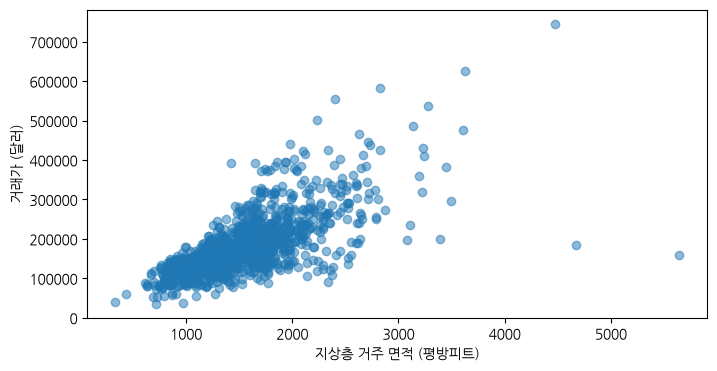

In [35]:
# [제공] 거주 면적과 거래가 (학습용 데이터)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(train_df["GrLivArea"], train_df["SalePrice"], alpha=0.5)
ax.set_xlabel("지상층 거주 면적 (평방피트)")
ax.set_ylabel("거래가 (달러)")
plt.show()

> **[판단]** 거래가와 가장 관련이 깊어 보이는 숫자 열 세 개를 적고, 왜 그럴지 한 줄씩 설명하세요.
>
> 나의 답: 상관계수 기준으로 OverallQual(0.79), GrLivArea(0.70), GarageCars(0.64)가 거래가와 가장 관련이 깊다.
> - OverallQual: 마감재와 시공 상태를 종합한 등급이라서, 같은 크기라도 품질이 좋은 집이 더 비싸게 팔리기 때문이다.
> - GrLivArea: 지상층 거주 면적이 넓을수록 쓸 수 있는 공간이 많아 가격이 올라가며, 산점도에서도 우상향 관계가 뚜렷하다.
> - GarageCars: 차고에 들어가는 차량 수가 많은 집은 대체로 큰 집이거나 고급 주택이라서 가격이 높다. 다만 이 열은 면적 같은 다른 정보의 대리 지표일 수 있어, 상관이 높다고 차고가 가격을 직접 올린다고 단정할 수는 없다.

> **[판단]** 산점도에서 눈에 띄는 점이 있나요? (예: 면적에 비해 값이 이상한 집) 이런 집을 모델에서 빼도 될까요, 두어야 할까요?
>
> 나의 답: 면적이 4,500 평방피트를 넘는데 거래가는 20만 달러 안팎으로 낮은 집 두 채가 눈에 띈다. 다른 집들의 우상향 추세에서 크게 벗어난 이상치다. 또 면적이 클수록 같은 면적에서도 거래가의 퍼짐이 커진다. 이 두 집은 면적 외의 이유(예: 거래 사정, 입력 오류)가 있을 수 있지만 지금은 근거가 없으므로, 일단 제거하지 않고 두되 이후 큰 오차가 나는 집 목록에서 다시 확인한다. 제거하면 평가가 좋아 보일 뿐 실제 서비스에서 만날 비슷한 집을 틀리게 된다.

---
# Part 2. 베이스라인 고르기

강의 2-1에서 회귀의 베이스라인은 "모든 집은 평균 가격"이라고 배웠습니다. 그런데 "평균 가격"만이 유일한 선택일까요?

## 2-1. 평균 예측과 중앙값 예측

**[직접 작성]** 학습용 데이터의 거래가 **평균**과 **중앙값**을 각각 평가용 집 전체의 예측값으로 쓴 두 베이스라인을 `evaluate`로 채점하고, 결과 지표를 `m_mean`, `m_median`에 저장하세요. 이어서 두 결과를 `log_result`로 기록합니다.

<details><summary>힌트</summary>

`mean_pred = np.full(len(test_df), train_df["SalePrice"].mean())`로 같은 값을 반복한 배열을 만듭니다. 중앙값도 같은 방식입니다.

`m_mean = evaluate("평균 예측", mean_pred)`, 그다음 `log_result("평균 예측", [], m_mean)`.
</details>

In [36]:
mean_pred = np.full(len(test_df), train_df["SalePrice"].mean())
median_pred = np.full(len(test_df), train_df["SalePrice"].median())

m_mean = evaluate("평균 예측", mean_pred)
m_median = evaluate("중앙값 예측", median_pred)

log_result("평균 예측", [], m_mean)
log_result("중앙값 예측", [], m_median)

[평균 예측] MAE 62,576 | RMSE 87,619 | R² -0.001 | MAPE 41.4%
[중앙값 예측] MAE 59,568 | RMSE 88,667 | R² -0.025 | MAPE 36.0%


> **[판단]** MAE와 RMSE에서 평균 예측과 중앙값 예측 중 어느 쪽이 더 낮은가요? 두 지표에서 결과가 다르다면, 왜 그럴지 "큰 오차를 얼마나 아프게 보는가"로 설명해 보세요.
>
> 나의 답: MAE는 중앙값 예측(59,568달러)이 평균 예측(62,576달러)보다 낮고, RMSE는 평균 예측(87,619달러)이 중앙값 예측(88,667달러)보다 낮다. MAE는 오차의 크기에 비례해 벌점을 주므로 큰 오차에 특별히 큰 벌점을 주지 않아 중앙값이 유리하다. RMSE는 오차를 제곱해 큰 오차에 훨씬 큰 벌점을 주는데, 거래가는 비싼 집이 소수 있어(평균 > 중앙값) 이런 집의 큰 오차를 줄여 주는 평균이 유리하다.

> **[판단]** 회귀 모델의 점수를 비교할 베이스라인으로는 둘 중 어느 것을 쓰겠습니까? 이유도 적으세요.
>
> 나의 답: 중앙값 예측을 베이스라인으로 쓰겠다. 거래가는 오른쪽으로 꼬리가 긴 분포라서 평균은 이상치의 영향을 크게 받지만, 중앙값은 이상치에 강건(robust)해 일반적인 집을 더 잘 대표한다. 실제로 중앙값 예측이 MAE(59,568달러)와 MAPE(36.0%)에서 평균 예측보다 낮아, 모델이 넘어야 할 기준으로 더 엄격하다. 다만 RMSE를 보고 지표로 정하면 평균 예측이 더 낮으므로, 베이스라인은 보고서의 평가 지표에 맞춰 선택해야 한다.

---
# Part 3. 현행 방법 만들기: 사람의 시세 규칙

모델이 없던 시절에도 중개사들은 나름의 규칙으로 시세를 매겼습니다. 비슷한 집의 평방피트당 단가에 면적을 곱하거나, 같은 동네의 비슷한 집이 얼마에 팔렸는지 떠올리는 식입니다. 여러분이 중개사라면 **정보 두세 개**로 어떤 규칙을 만들겠습니까?

**시세 규칙**: 어떤 정보를 어떻게 쓸지 **내가 정하고**, 숫자(동네별 단가 등)는 학습용 데이터에서 계산하는 방법입니다. Chapter 1에서 배운 규칙 기반(Rule-Based) 방법의 한 예로, 모델이 이겨야 할 비교 기준이 됩니다.

## 시세 규칙을 만들 때의 약속

- 쓰는 정보는 **두세 개를 넘기지 않습니다.** 머릿속으로 계산할 수 있어야 하기 때문입니다.
- 시세 규칙에 쓰는 숫자(동네별 단가, 구간별 중앙값 등)는 **학습용 데이터에서만** 계산합니다.
- 평가용 데이터를 보고 시세 규칙을 고치지 않습니다.

## 3-1. 나의 시세 규칙 만들기

> **[판단]** 나의 시세 규칙(말로): 집의 **품질 등급(OverallQual)**과 **거주 면적(GrLivArea)**을 보고, **같은 품질 등급 집들의 평방피트당 단가 중앙값**을 기준으로 가격을 정한다.
>
> 이 정보를 고른 근거(1-6의 어떤 결과인가): 숫자 열 중 거래가와의 상관이 가장 높은 열이 OverallQual(0.79)과 GrLivArea(0.70)였고, 산점도에서도 면적이 클수록 거래가가 오르는 관계가 뚜렷했다.
>
> 나의 답: 품질 등급으로 집의 수준을, 면적으로 크기를 반영하는 두 가지 정보만 쓰는 단순한 규칙이다. 단가는 학습용 데이터에서만 계산했고, 이상치에 강건한 중앙값을 썼다. 한계는 같은 품질 등급이라도 동네나 건축 연도에 따른 가격 차이를 반영하지 못한다는 점이다.

**[직접 작성]** 시세 규칙을 코드로 옮겨 평가용 집의 가격을 계산하고, 예측을 `rule_pred`(평가용 `test_df`와 같은 순서의 `Series`)에 저장하세요. 그다음 `evaluate`로 채점하고, 결과를 `m_rule`에 저장한 뒤 `log_result`로 기록합니다.

<details><summary>힌트</summary>

학습용 데이터에서 평방피트당 단가를 구하는 예시입니다.

```python
unit_price = (train_df["SalePrice"] / train_df["GrLivArea"]).median()
rule_pred = test_df["GrLivArea"] * unit_price
```

동네별로 단가를 다르게 쓰려면 단가를 동네별로 구한 뒤 `map`으로 붙입니다.

```python
unit_by_nb = (train_df["SalePrice"] / train_df["GrLivArea"]).groupby(train_df["Neighborhood"]).median()
rule_pred = test_df["Neighborhood"].map(unit_by_nb) * test_df["GrLivArea"]
```

이 예시는 형식만 보여 주는 것입니다. 여러분의 시세 규칙을 쓰세요. 평가용에만 있는 동네가 있을 수 있으니, 빈 값이 생기면 `fillna(train_df["SalePrice"].median())`처럼 채우세요.
</details>

In [37]:
unit_price = train_df["SalePrice"] / train_df["GrLivArea"]
unit_by_qual = unit_price.groupby(train_df["OverallQual"]).median()   # 학습용으로만 계산

rule_unit = test_df["OverallQual"].map(unit_by_qual).fillna(unit_price.median())
rule_pred = rule_unit * test_df["GrLivArea"]

m_rule = evaluate("내 시세 규칙", rule_pred)
log_result("내 시세 규칙", [], m_rule)

[내 시세 규칙] MAE 32,665 | RMSE 44,289 | R² 0.744 | MAPE 21.0%


> **[판단]** 내 시세 규칙의 MAE는 베이스라인(평균·중앙값 예측)보다 얼마나 낮은가요? 정보 두세 개만으로 오차가 이만큼 줄어든다는 것은 무엇을 뜻할까요?
>
> 나의 답: 내 시세 규칙의 MAE는 32,665달러로, 평균 예측(62,576달러)보다 약 48%, 중앙값 예측(59,568달러)보다 약 45% 낮다. RMSE(44,289달러)와 MAPE(21.0%)도 베이스라인보다 낮고, R²는 0.744로 거래가 변동의 약 74%를 설명한다. 즉 품질 등급과 거주 면적 두 가지 정보만으로도 거래가의 상당 부분을 예측할 수 있다. 따라서 이후 모델은 이 규칙보다 오차가 낮은지로 비교해야 한다.

---
# Part 4. 모델 만들기와 실험 기록

이제 모델을 만들어 내 시세 규칙과 겨룹니다. 강의 Part 2의 코드를 보지 말고 먼저 직접 써 보세요.

## 4-1. 첫 모델: 다중회귀

**[직접 작성]** 아래 순서로 작성하세요.

1. 피처 `["GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars"]`로 `make_data`를 호출해 `X_train, X_test, y_train, y_test`를 만든다
2. `LinearRegression`을 학습한다
3. 학습용과 평가용을 모두 `evaluate`로 채점한다 (학습용은 `y_true=y_train`을 줍니다)
4. 평가용 결과를 `log_result`로 기록한다

<details><summary>힌트</summary>

강의 2-3의 코드와 같은 순서입니다.

```python
m_train = evaluate("학습용", model.predict(X_train), y_true=y_train)
m_test = evaluate("다중회귀 5개", model.predict(X_test))
log_result("다중회귀 5개", features, m_test, m_train)
```
</details>

In [38]:
features = ["GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars"]

X_train, X_test, y_train, y_test = make_data(features)

model = LinearRegression()
model.fit(X_train, y_train)

m_train = evaluate("학습용", model.predict(X_train), y_true=y_train)
m_test = evaluate("다중회귀 5개", model.predict(X_test))

log_result("다중회귀 5개", features, m_test, m_train)

[학습용] MAE 24,399 | RMSE 37,970 | R² 0.758 | MAPE 14.5%
[다중회귀 5개] MAE 25,415 | RMSE 39,763 | R² 0.794 | MAPE 15.3%


> **[판단]** 이 모델의 학습용 점수와 평가용 점수는 얼마나 차이 나나요? 그 차이는 과적합의 신호일까요?
>
> 나의 답: 평가용(다중회귀 5개) 오차가 학습용보다 조금 늘었다. MAE는 24,399달러에서 25,415달러로 약 4%, RMSE는 37,970달러에서 39,763달러로 약 5% 커졌다. 과적합이라면 학습용 점수만 크게 좋고 평가용 점수가 크게 나빠져야 하는데 그 차이가 작으므로, 과적합의 신호로 보기 어렵다.

## 4-2. 피처와 모델을 바꿔 보기

피처를 늘리거나 모델의 복잡도를 바꿔 가며 **세 번 이상** 실험하세요. 매번 아래 `run`이 학습용·평가용 점수를 모두 채점해 기록해 줍니다.

**[직접 작성]** `run(이름, 피처 목록, 모델)`을 세 번 이상 호출하세요. 다음 세 가지를 모두 포함하면 좋습니다.

- 숫자 피처만 늘려 보기
- 범주형 피처(동네, 마감 품질 등)를 더해 보기
- 모델의 복잡도를 올려 보기 (다항 피처)와, 그에 벌점을 주는 Ridge

<details><summary>힌트</summary>

```python
run("숫자 12개", num_features, LinearRegression())
run("숫자+범주", num_features + cat_features, LinearRegression())
run("3차 다항", num_features, make_pipeline(StandardScaler(), PolynomialFeatures(3), LinearRegression()))
run("3차 다항 + Ridge", num_features, make_pipeline(StandardScaler(), PolynomialFeatures(3), Ridge(alpha=100)))
```

`alpha`(벌점의 세기)를 10, 100, 1000으로 바꿔 보면 학습용·평가용 점수가 어떻게 달라지는지 볼 수 있습니다.
</details>

In [39]:
# 실험 1: 숫자 피처만 늘리기 (5개 → 12개)
run("숫자 12개", num_features, LinearRegression())

# 실험 2: 범주형 피처 더하기
run("숫자+범주", num_features + cat_features, LinearRegression())

# 실험 3: 모델 복잡도 올리기 (3차 다항)
run("3차 다항", num_features,
    make_pipeline(StandardScaler(), PolynomialFeatures(3), LinearRegression()))

# 실험 4: 같은 3차 다항에 Ridge로 벌점 주기
run("3차 다항 + Ridge", num_features,
    make_pipeline(StandardScaler(), PolynomialFeatures(3), Ridge(alpha=100)))

[숫자 12개 (학습용)] MAE 22,972 | RMSE 36,605 | R² 0.775 | MAPE 13.7%
[숫자 12개] MAE 24,353 | RMSE 39,231 | R² 0.799 | MAPE 14.5%
[숫자+범주 (학습용)] MAE 18,428 | RMSE 29,716 | R² 0.852 | MAPE 10.6%
[숫자+범주] MAE 20,172 | RMSE 32,698 | R² 0.861 | MAPE 11.9%
[3차 다항 (학습용)] MAE 11,736 | RMSE 16,646 | R² 0.954 | MAPE 7.2%
[3차 다항] MAE 29,235 | RMSE 67,319 | R² 0.409 | MAPE 17.8%
[3차 다항 + Ridge (학습용)] MAE 13,872 | RMSE 19,911 | R² 0.934 | MAPE 8.5%
[3차 다항 + Ridge] MAE 20,222 | RMSE 32,073 | R² 0.866 | MAPE 12.3%


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('polynomialfeatures', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['GrLivArea','OverallQual','YearBuilt',...,'TotRmsAbvGrd','Fireplaces', '1stFlrSF']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [40]:
from sklearn.model_selection import cross_val_score

# 파생 피처 추가 (df에 열을 더해도 make_data가 df를 쓰므로 그대로 동작)
df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]

def cv_mae(features, model):
    X_tr, _, y_tr, _ = make_data(features)          # 학습용만 사용
    s = cross_val_score(model, X_tr, y_tr, cv=5, scoring="neg_mean_absolute_error")
    return -s.mean()

base = num_features + cat_features
print("기준:", round(cv_mae(base, LinearRegression())))
print("+TotalSF:", round(cv_mae(base + ["TotalSF"], LinearRegression())))
print("+HouseAge:", round(cv_mae(base + ["HouseAge"], LinearRegression())))

기준: 19742
+TotalSF: 19769
+HouseAge: 19790


**[제공]** 실험 기록표를 평가 MAE 순으로 봅니다.

In [41]:
# [제공] 실험 기록표
pd.DataFrame(experiment_log).sort_values("평가 MAE")

,실험,피처 수,학습 MAE,학습 RMSE,평가 MAE,평가 RMSE,평가 R²
5,숫자+범주,18,18428.0,29716.0,20172,32698,0.861
7,3차 다항 + Ridge,12,13872.0,19911.0,20222,32073,0.866
4,숫자 12개,12,22972.0,36605.0,24353,39231,0.799
3,다중회귀 5개,5,24399.0,37970.0,25415,39763,0.794
6,3차 다항,12,11736.0,16646.0,29235,67319,0.409
2,내 시세 규칙,-,NaN,NaN,32665,44289,0.744
1,중앙값 예측,-,NaN,NaN,59568,88667,-0.025
0,평균 예측,-,NaN,NaN,62576,87619,-0.001


> **[판단]** 범주형 피처(동네, 마감 품질 등)를 더했을 때 오차가 얼마나 줄었나요? 이 피처들이 왜 도움이 되었을까요?
>
> 나의 답: 숫자 12개 모델(평가 MAE 24,353달러)에 범주형을 더하자 20,172달러로 약 17% 줄었다. 동네(입지)와 마감 품질(집 상태)은 숫자 피처에 없던 정보라서 도움이 된 것으로 보인다.

> **[판단]** 학습용 점수와 평가용 점수의 차이가 가장 큰 실험은 무엇인가요? Ridge를 쓰면 그 차이가 어떻게 달라졌나요? 강의 Part 3의 "과적합"과 "정규화"로 설명해 보세요.
>
> 나의 답: 차이가 가장 큰 실험은 3차 다항이다. 학습 MAE 11,736달러에 평가 MAE 29,235달러로, 학습 데이터에 비해 항이 너무 많아 잡음까지 맞춘 과적합이다. Ridge를 쓰자 평가 MAE가 20,222달러로 약 31% 줄고 학습 MAE는 13,872달러로 올라 차이가 줄었다. 정규화가 계수에 벌점을 주어 모델의 복잡도를 억제한 결과다.

> **[판단]** 가장 좋은 모델은 내 시세 규칙보다 MAE가 얼마나(달러, %) 낮은가요? 이 차이라면 기획팀이 모델을 도입할 만할까요?
>
> 나의 답: 가장 좋은 모델("숫자+범주", 평가 MAE 20,172달러)은 내 시세 규칙(32,665달러)보다 12,493달러(약 38%) 낮다. 도입을 검토할 만한 차이이지만, 어느 가격대에서 크게 틀리는지는 5-1에서 확인해야 한다.

## 4-3. Lasso: 피처를 고르는 정규화

4-2의 Ridge는 계수를 **고르게 줄이는** 정규화였습니다. **Lasso**는 벌점의 모양이 달라서, 덜 중요한 계수를 **정확히 0**으로 만듭니다. 계수가 0인 피처는 모델에서 빠진 것과 같으므로, Lasso는 정규화이면서 동시에 피처를 고르는 방법입니다.

| | Ridge | Lasso |
| --- | --- | --- |
| 벌점 | 계수의 제곱합 | 계수의 절댓값합 |
| 계수가 줄어드는 방식 | 모두 고르게, 0이 되지는 않음 | 덜 중요한 것부터 정확히 0 |

이 절에서는 Lasso가 실제로 어떤 피처를 버리는지 세 가지 실험으로 확인합니다. 세 실험 모두 실험 기록표(`experiment_log`)에는 남기지 않습니다.

### 실험 1. 계수 비교: 무엇이 0이 되는가

**[직접 작성]** 숫자 피처 12개(`num_features`)로 세 모델을 학습하고, 계수를 한 표로 비교하세요. 세 모델 모두 `StandardScaler`를 앞에 붙입니다(표준화해야 계수끼리 비교할 수 있습니다).

- 선형회귀 (`LinearRegression()`)
- Ridge (`Ridge(alpha=100)`)
- Lasso (`Lasso(alpha=5000)`)

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features)
coefs = {}
for name, reg in [("선형회귀", LinearRegression()), ("Ridge 100", Ridge(alpha=100)), ("Lasso 5000", Lasso(alpha=5000))]:
    m = make_pipeline(StandardScaler(), reg).fit(X_tr, y_tr)
    coefs[name] = m[-1].coef_          # 파이프라인의 마지막 단계(모델)의 계수
pd.DataFrame(coefs, index=X_tr.columns).round(0)
```

`m[-1]`은 파이프라인의 마지막 단계, 즉 모델입니다.
</details>

In [42]:
X_tr, X_te, y_tr, y_te = make_data(num_features)

coefs = {}
for name, reg in [("선형회귀", LinearRegression()),
                  ("Ridge 100", Ridge(alpha=100)),
                  ("Lasso 5000", Lasso(alpha=5000))]:
    m = make_pipeline(StandardScaler(), reg).fit(X_tr, y_tr)
    coefs[name] = m[-1].coef_      # 파이프라인의 마지막 단계(모델)의 계수

pd.DataFrame(coefs, index=X_tr.columns).round(0)

,선형회귀,Ridge 100,Lasso 5000
GrLivArea,21092.0,16753.0,19576.0
OverallQual,26459.0,23642.0,27385.0
YearBuilt,8745.0,8074.0,5089.0
YearRemodAdd,7366.0,7685.0,4259.0
TotalBsmtSF,6347.0,6859.0,5948.0
GarageCars,7082.0,6667.0,6992.0
GarageArea,3930.0,5248.0,3068.0
LotArea,6052.0,5598.0,2517.0
FullBath,-3116.0,-790.0,0.0
TotRmsAbvGrd,1805.0,4033.0,0.0


> **[판단]** Lasso가 0으로 만든 피처는 무엇인가요? 그 피처들은 집값과 정말 관계가 없을까요? 1-6의 상관표나 다른 피처와의 관계를 떠올려 설명해 보세요.
>
> 나의 답: Lasso가 0으로 만든 피처는 FullBath와 TotRmsAbvGrd다. 그렇다고 집값과 관계가 없는 것은 아니다. 1-6 상관표에서 TotRmsAbvGrd는 0.52, FullBath는 0.55로 거래가와 상관이 꽤 높았다. 방과 욕실 수는 거주 면적(GrLivArea)이 클수록 늘어나는 정보라서, 면적이 이미 들어 있으면 새로 더해 주는 정보가 적어 Lasso가 뺀 것으로 보인다. 선형회귀에서 FullBath 계수가 -3,116달러로 음수인 것도 피처끼리 겹쳐서 계수가 불안정해진 신호로 보인다. 즉 0이라는 것은 "관계가 없다"가 아니라 "다른 피처가 있을 때 추가로 필요하지 않다"는 뜻이다.

### 실험 2. 잡음 피처를 섞으면

**[제공]** 아무 의미 없는 무작위 숫자 열 5개(`noise0`~`noise4`)를 데이터에 추가합니다. 집값과 전혀 관계가 없는 열입니다.

In [43]:
# [제공] 무작위 잡음 피처 5개 추가 (씨앗 고정)
rng = np.random.RandomState(0)
noise_features = [f"noise{i}" for i in range(5)]
for col in noise_features:
    df[col] = rng.randn(len(df))
print(df[noise_features].describe().round(2).loc[["mean", "std"]])

      noise0  noise1  noise2  noise3  noise4
mean   -0.02   -0.03   -0.02    0.02   -0.02
std     0.98    0.96    1.01    0.99    0.99


**[직접 작성]** `num_features + noise_features`로 선형회귀와 Lasso(`alpha=1000`)를 학습하세요. 각 모델에서

1. 잡음 피처 5개의 계수
2. 계수가 정확히 0이 된 피처 목록
3. 평가용 점수 (`evaluate`로 채점)

를 출력합니다.

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features + noise_features)
m = make_pipeline(StandardScaler(), Lasso(alpha=1000)).fit(X_tr, y_tr)
coef = pd.Series(m[-1].coef_, index=X_tr.columns)
print(coef[noise_features].round(0))
print("0이 된 피처:", list(coef[coef == 0].index))
evaluate("Lasso + 잡음", m.predict(X_te))
```
</details>

In [44]:
X_tr, X_te, y_tr, y_te = make_data(num_features + noise_features)

for name, reg in [("선형회귀", LinearRegression()), ("Lasso 1000", Lasso(alpha=1000))]:
    m = make_pipeline(StandardScaler(), reg).fit(X_tr, y_tr)
    coef = pd.Series(m[-1].coef_, index=X_tr.columns)

    print(f"=== {name} ===")
    print("잡음 피처 계수:")
    print(coef[noise_features].round(0))
    print("0이 된 피처:", list(coef[coef == 0].index))
    evaluate(f"{name} + 잡음", m.predict(X_te))
    print()

=== 선형회귀 ===
잡음 피처 계수:
noise0   -696.0
noise1    497.0
noise2   -144.0
noise3   -732.0
noise4   -175.0
dtype: float64
0이 된 피처: []
[선형회귀 + 잡음] MAE 24,300 | RMSE 39,230 | R² 0.799 | MAPE 14.5%

=== Lasso 1000 ===
잡음 피처 계수:
noise0   -0.0
noise1    0.0
noise2    0.0
noise3   -0.0
noise4   -0.0
dtype: float64
0이 된 피처: ['FullBath', 'noise0', 'noise1', 'noise2', 'noise3', 'noise4']
[Lasso 1000 + 잡음] MAE 24,184 | RMSE 39,522 | R² 0.796 | MAPE 14.3%



> **[판단]** 선형회귀는 잡음 피처에 어떤 계수를 주었나요? 이 계수표만 보고 보고서를 쓰면 어떤 오해가 생길까요? Lasso는 잡음을 어떻게 다뤘고, 평가용 점수는 어떻게 달라졌나요?
>
> 나의 답: 선형회귀는 의미 없는 잡음 피처에 -732달러~497달러의 0이 아닌 계수를 주었다(noise3 -732, noise0 -696, noise1 497 등). 이 표만 보고 보고서를 쓰면 "잡음 변수가 집값에 영향을 준다"고 잘못 해석할 수 있다. 계수가 0이 아니라는 것이 관계가 있다는 증거는 아니다. Lasso(alpha=1000)는 잡음 피처 5개의 계수를 모두 0으로 만들어 걸러 냈고(FullBath도 0), 평가용 점수는 MAE 24,300달러(선형회귀)에서 24,184달러로, RMSE는 39,230달러에서 39,522달러로 거의 달라지지 않았다. 점수를 거의 잃지 않으면서 쓸모없는 피처를 제거한 셈이다.

### 실험 3. 범주형까지 넣은 모델에 Lasso를 걸면

**[직접 작성]** 4-2에서 가장 좋았던 피처 조합(`num_features + cat_features`, 원핫 인코딩 후 열 67개)에 Lasso를 걸고, `alpha`를 100, 300, 1000, 3000으로 바꿔 가며 다음을 표로 정리하세요.

- 0이 아닌 계수의 수
- 평가용 MAE와 RMSE

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features + cat_features)
rows = []
for a in [100, 300, 1000, 3000]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=100000)).fit(X_tr, y_tr)
    p = m.predict(X_te)
    rows.append({"alpha": a, "남은 피처 수": int((m[-1].coef_ != 0).sum()),
                 "평가 MAE": round(mean_absolute_error(y_te, p)),
                 "평가 RMSE": round(np.sqrt(mean_squared_error(y_te, p)))})
pd.DataFrame(rows)
```

비교 기준은 실험 기록표의 "숫자+범주"(선형회귀) 줄입니다.
</details>

In [45]:
X_tr, X_te, y_tr, y_te = make_data(num_features + cat_features)

rows = []
for a in [100, 300, 1000, 3000]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=100000)).fit(X_tr, y_tr)
    p = m.predict(X_te)
    rows.append({"alpha": a,
                 "남은 피처 수": int((m[-1].coef_ != 0).sum()),
                 "평가 MAE": round(mean_absolute_error(y_te, p)),
                 "평가 RMSE": round(np.sqrt(mean_squared_error(y_te, p)))})

pd.DataFrame(rows)

,alpha,남은 피처 수,평가 MAE,평가 RMSE
0,100,58,20090,32704
1,300,49,20030,32767
2,1000,35,19946,33056
3,3000,24,20717,34903


> **[판단]** Lasso는 "숫자+범주" 선형회귀보다 나아졌나요? MAE와 RMSE가 같은 방향으로 움직였나요? 4-2의 3차 다항 실험에서 Ridge가 큰 효과를 냈던 것과 비교해, 여기서 효과가 작은 이유를 "이 모델이 과적합했는가"로 설명해 보세요.
>
> 나의 답: 크게 나아지지 않았고, 두 지표가 반대로 움직였다. 기준인 "숫자+범주" 선형회귀(MAE 20,172달러, RMSE 32,698달러)와 비교하면 alpha 100~1000에서 MAE는 82~226달러(최대 약 1%) 낮아졌지만 RMSE는 6~358달러 올랐다. alpha 3000에서는 MAE(20,717달러)와 RMSE(34,903달러) 모두 나빠졌다. 4-2의 3차 다항에서는 모델이 학습 데이터에 과적합해 Ridge가 평가 MAE를 29,235달러에서 20,222달러로 크게 줄였지만, 이 모델은 선형회귀라 과적합이 크지 않았다(학습 MAE 18,428달러, 평가 MAE 20,172달러). 줄일 과적합이 적으니 정규화의 효과도 작았다.

> **[판단]** 기획팀이 "피처를 절반만 써도 비슷하다면 더 단순한 모델이 낫지 않나요?"라고 묻습니다. 어떻게 답하겠습니까?
>
> 나의 답: 맞는 말씀입니다. 이 데이터에서는 절반 정도만 써도 정확도가 거의 같았습니다. 모델이 쓰는 입력 항목을 67개에서 35개로 줄였더니(약 절반), 평균적으로 틀리는 금액이 20,172달러에서 19,946달러로 거의 달라지지 않았습니다. 항목이 적으면 매물 등록 때 입력받을 정보가 줄고, 모델이 왜 그 가격을 냈는지 설명하기도 쉬워서 단순한 쪽이 유리합니다. 다만 항목을 더 줄여 24개로 하면 평균 오차가 20,717달러로 늘고, 크게 빗나가는 경우도 눈에 띄게 많아져서(RMSE 33,056달러 → 34,903달러) 줄이는 데에는 한계가 있습니다. 그래서 35개 안팎까지 줄이는 것을 권합니다.

---
# Part 5. 오차 들여다보기와 보고

지표 하나로는 "믿어도 되는 집"과 "믿으면 안 되는 집"을 구분할 수 없습니다. 오차가 어디에 몰려 있는지 직접 봅니다.

## 5-1. 가격대별 오차

**[직접 작성]** 기록표에서 평가 MAE가 가장 낮은 실험을 골라 그 이름을 `best_name`에 저장하고, 그 실험의 예측을 `best_pred`에 저장하세요. 그다음 `error_by_price`로 **내 시세 규칙**과 **최고 모델**의 가격대별 오차를 각각 출력합니다.

<details><summary>힌트</summary>

모든 실험의 예측은 `preds`에 이름으로 저장되어 있습니다. `best_name = "숫자+범주"`처럼 이름을 직접 적고 `best_pred = preds[best_name]`로 꺼내세요.

`error_by_price(preds["내 시세 규칙"])`, `error_by_price(best_pred)`
</details>

In [46]:
best_name = "숫자+범주"          # 기록표에서 평가 MAE가 가장 낮은 실험 (20,172)
best_pred = preds[best_name]

print("=== 내 시세 규칙 ===")
print(error_by_price(preds["내 시세 규칙"]))

print("\n=== 최고 모델:", best_name, "===")
print(error_by_price(best_pred))

=== 내 시세 규칙 ===
                  집 수       MAE  평균 편향(실제−예측)
SalePrice                                    
(0, 100000]        26   28236.0      -19066.0
(100000, 200000]  184   27126.0       -4890.0
(200000, 300000]   58   41485.0       -5999.0
(300000, 500000]   21   52417.0       21064.0
(500000, 800000]    3  102005.0      102005.0

=== 최고 모델: 숫자+범주 ===
                  집 수       MAE  평균 편향(실제−예측)
SalePrice                                    
(0, 100000]        26   20945.0      -14409.0
(100000, 200000]  184   13752.0       -2168.0
(200000, 300000]   58   24376.0        3782.0
(300000, 500000]   21   38577.0       25190.0
(500000, 800000]    3  197086.0      197086.0


> **[판단]** 어느 가격대에서 오차(MAE)가 가장 큰가요? 그 가격대의 "평균 편향"은 양수(실제가 더 비쌈)인가요, 음수인가요? 모델과 시세 규칙이 같은 방향으로 틀리나요?
>
> 나의 답: MAE가 가장 큰 가격대는 50만~80만 달러로, 최고 모델 197,086달러, 시세 규칙 102,005달러다. 이 가격대의 평균 편향은 두 방법 모두 양수(모델 +197,086, 규칙 +102,005)라서 실제가 예측보다 비싸다. 편향이 MAE와 같으므로 3채 모두 예측이 실제보다 낮았다. 모델과 시세 규칙은 같은 방향으로 틀리며, 30만 달러 초과 구간에서는 둘 다 양수(과소 예측), 10만 달러 이하 구간에서는 둘 다 음수(과대 예측)다. 즉 비싼 집은 싸게, 싼 집은 비싸게 예측하는 경향이 있다. 다만 50만 달러 초과는 3채뿐이라 숫자를 일반화하기는 어렵다.

## 5-2. 잔차 그림

**[직접 작성]** 최고 모델의 잔차(실제 − 예측)를 예측 가격에 대해 산점도로 그리세요. 0을 나타내는 가로선도 함께 그립니다.

<details><summary>힌트</summary>

강의 2-7의 코드와 같습니다.

```python
residual = y_test - best_pred
plt.scatter(best_pred, residual, alpha=0.5)
plt.axhline(0, color="gray")
```
</details>

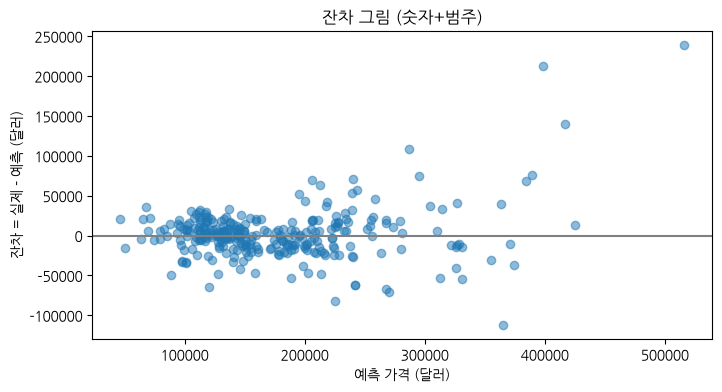

In [47]:
residual = y_test - best_pred

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(best_pred, residual, alpha=0.5)
ax.axhline(0, color="gray")
ax.set_xlabel("예측 가격 (달러)")
ax.set_ylabel("잔차 = 실제 - 예측 (달러)")
ax.set_title(f"잔차 그림 ({best_name})")
plt.show()

> **[판단]** 잔차 그림에서 규칙이 보이나요? 예측 가격이 높은 쪽에서 점들이 어떻게 흩어져 있나요?
>
> 나의 답: 예측 가격이 높아질수록 점들이 0선 위아래로 넓게 퍼지는 부채꼴 모양이다. 비싼 집(예측 40만 달러 이상)은 대부분 0선 위에 있어, 실제가 예측보다 더 비싸고 오차도 크다.

## 5-3. 가장 크게 틀린 집 들여다보기

**[직접 작성]** 최고 모델이 가장 크게 틀린 집 10채를 골라 실제 거래가, 예측 가격, 면적(`GrLivArea`), 품질(`OverallQual`), 동네(`Neighborhood`)를 한 표로 출력하세요.

<details><summary>힌트</summary>

`test_df.assign(예측=best_pred, 오차=y_test - best_pred)`로 열을 붙인 뒤, 오차의 절댓값으로 정렬합니다. `sort_values("오차", key=abs, ascending=False).head(10)`.
</details>

In [48]:
worst = (test_df.assign(예측=best_pred, 오차=y_test - best_pred)
                .sort_values("오차", key=abs, ascending=False)
                .head(10))

worst[["SalePrice", "예측", "오차", "GrLivArea", "OverallQual", "Neighborhood"]].round(0)

,SalePrice,예측,오차,GrLivArea,OverallQual,Neighborhood
691,755000,516019.0,238981.0,4316,10,NoRidge
898,611657,398955.0,212702.0,2364,9,NridgHt
1046,556581,417006.0,139575.0,2868,9,StoneBr
581,253293,365415.0,-112122.0,2042,8,NridgHt
774,395000,286980.0,108020.0,1973,8,NridgHt
588,143000,225154.0,-82154.0,1473,5,ClearCr
1243,465000,389555.0,75445.0,2076,10,NridgHt
585,369900,295269.0,74631.0,2028,8,Timber
218,311500,240172.0,71328.0,1954,7,Crawfor
1173,200500,270721.0,-70221.0,3086,5,ClearCr


> **[판단]** 크게 틀린 집들에게 공통점이 있나요? 기획팀이 "이런 매물에는 자동 시세를 쓰지 말자"고 한다면 어떤 기준(가격대, 품질 등)을 제안하겠습니까?
>
> 나의 답: 크게 틀린 10채 중 7채는 실제 거래가가 30만 달러 이상이고, 품질(OverallQual)이 8 이상인 집도 7채다(상위 5채는 모두 8 이상). 동네도 NridgHt, NoRidge, StoneBr 같은 고가 동네에 몰려 있고, 7채는 실제가 예측보다 비쌌다. 따라서 "예측 가격 30만 달러 이상이거나 품질 8 이상"인 매물에는 자동 시세를 쓰지 말자고 제안한다. 다만 10채만 본 결과라 경향으로 봐야 한다.

## 5-4. 가격 맞히기

곧 다른 수강생들의 결과와 함께 비교합니다. 그 전에 **사람의 감**으로 세 채의 가격을 먼저 맞혀 봅니다.

**[제공]** 평가용 집 세 채의 정보를 보여 줍니다. (거래가는 보여 주지 않습니다.)

In [49]:
# [제공] 맞혀 볼 집 세 채 (거래가는 숨김)
_s = test_df.sort_values("SalePrice")
guess_ids = [_s.index[int(q * (len(_s) - 1))] for q in (0.05, 0.5, 0.99)]
show_cols = ["Neighborhood", "GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars", "KitchenQual"]
test_df.loc[guess_ids, show_cols]

,Neighborhood,GrLivArea,OverallQual,YearBuilt,TotalBsmtSF,GarageCars,KitchenQual
649,MeadowV,630,4,1970,630,0,TA
1299,NAmes,1246,5,1959,1246,1,Gd
1243,NridgHt,2076,10,2006,2076,3,Ex


**[직접 작성]** 위 표만 보고, 세 집의 거래가를 직관으로 적으세요. (`my_guess`의 0을 달러 숫자로 바꿉니다.)

In [57]:
# 위 표의 순서대로 세 집의 거래가(달러)를 적으세요
# my_guess = {guess_ids[0]: 0, guess_ids[1]: 0, guess_ids[2]: 0}
my_guess = {guess_ids[0]: 90000, guess_ids[1]: 150000, guess_ids[2]: 380000} 

**[제공]** 실제 거래가를 공개합니다. 내 감, 내 시세 규칙, 최고 모델의 예측을 나란히 봅니다.

In [58]:
# [제공] 정답 공개
reveal = pd.DataFrame({
    "실제 거래가": y_test.loc[guess_ids],
    "내 감": pd.Series(my_guess),
    "내 시세 규칙": preds["내 시세 규칙"].loc[guess_ids],
    "최고 모델": best_pred.loc[guess_ids],
})
for col in ["내 감", "내 시세 규칙", "최고 모델"]:
    reveal[col + " 오차"] = (reveal[col] - reveal["실제 거래가"]).abs()
reveal.round(0)

,실제 거래가,내 감,내 시세 규칙,최고 모델,내 감 오차,내 시세 규칙 오차,최고 모델 오차
649,84500,90000,62612.0,79394.0,5500,21888.0,5106.0
1299,154000,150000,145079.0,140022.0,4000,8921.0,13978.0
1243,465000,380000,345536.0,389555.0,85000,119464.0,75445.0


> **[판단]** 세 방법(내 감, 내 시세 규칙, 모델) 중 가장 가까웠던 것은 무엇인가요? 가장 비싼 집에서는 어땠나요? 5-1의 결과와 연결해서 설명해 보세요.
>
> 나의 답: 세 집 평균 오차는 감 약 31,500달러, 모델 약 31,510달러, 규칙 약 50,091달러로 감과 모델이 비슷했다. 가장 비싼 집(465,000달러)에서는 세 방법 모두 실제보다 낮게 예측했고(감 85,000, 규칙 119,464, 모델 75,445달러 오차), 5-1에서 30만 달러 초과 구간의 평균 편향이 양수였던 것과 같은 방향이다.

## 5-5. 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 틀려도 괜찮습니다. 예상이 빗나간 지점이 가장 많이 배우는 곳입니다.

시세 규칙은 나의 시세 규칙 하나만 있는 것이 아닙니다. 다른 정보를 골랐다면 결과도 달랐을 것입니다. 다음 절에서는 아래 **후보 정보 5개** 중 1개 또는 2개를 고르고, **계산법 2가지** 중 하나를 쓰는 시세 규칙을 **모두** 만들어 채점합니다. 정보 조합 5 + 10 = 15가지 × 계산법 2가지 = **30개**입니다.

| 후보 정보 | 나누는 방법 |
| --- | --- |
| 동네 (`Neighborhood`) | 동네 이름 그대로 |
| 품질 등급 (`OverallQual`) | 1~10 등급 그대로 |
| 거주 면적 (`GrLivArea`) | 학습용 기준 5구간 (집 수가 같도록) |
| 건축 연도 (`YearBuilt`) | 학습용 기준 5구간 (집 수가 같도록) |
| 차고 차량 수 (`GarageCars`) | 0~4대 그대로 |

| 계산법 | 뜻 |
| --- | --- |
| (가) 그룹 중앙값 | 같은 그룹 집들의 거래가 중앙값을 그대로 시세로 쓴다 |
| (나) 그룹 단가 × 면적 | 같은 그룹 집들의 평방피트당 단가 중앙값에 그 집의 거주 면적을 곱한다 |

예: "동네 + 품질 등급, (가)"는 "같은 동네·같은 품질 등급 집들의 거래가 중앙값"을 시세로 쓰는 규칙입니다. 모든 그룹의 숫자는 학습용 데이터에서만 계산합니다.

> **[판단]** 예상 ① 기록표에서 가장 좋은 모델(평가 MAE 약 20,000달러)은 시세 규칙 30개 중 몇 개보다 MAE가 낮을까요?
>
> 나의 답: 대부분의 시세 규칙보다 MAE가 낮을 것 같다. 약 25~28개를 이길 것으로 예상한다. 내 시세 규칙(품질 등급 + 단가 × 면적)의 MAE 32,665달러보다 모델(20,172달러)이 약 38% 낮았고, 규칙은 정보를 1~2개만 쓰는 반면 모델은 18개 피처를 쓰기 때문이다. 다만 동네나 품질을 함께 쓰는 2개 정보 규칙 중에는 모델에 가까운 것이 있을 수 있다.

> **[판단]** 예상 ② 30개 중 MAE가 가장 낮은 시세 규칙은 어떤 정보를 쓰고, 어떤 계산법일까요? 이유도 적어 보세요.
>
> 나의 답: "품질 등급 + 동네, (나) 그룹 단가 × 면적"일 것 같다. 품질과 동네는 거래가에 대한 정보가 서로 달라서(상관표 상위 1위와 동네별 중앙값 차이), 함께 쓰면 오차가 가장 많이 줄 것이다. (나)는 같은 그룹 안에서도 면적 차이를 반영하므로 (가)보다 유리하다. 다만 품질×동네로 그룹을 나누면 집 수가 적은 그룹이 많아 단가가 불안정할 수 있다.

## 5-6. 시세 규칙 30개 채점하기

**[직접 작성]** `my_rule_text`에 나의 시세 규칙을 한 줄로 적으세요. 아래 결과에서 나의 시세 규칙을 표시할 때 씁니다. (예: `"동네별 평방피트당 단가 × 거주 면적"`)

In [59]:
my_rule_text = "품질 등급별 평방피트당 단가 중앙값 × 거주 면적"

**[제공]** 후보 정보 5개 중 1~2개 × 계산법 2가지로 시세 규칙 30개를 만들고, 평가용 데이터에서 채점합니다.

In [60]:
# [제공] 시세 규칙 30개 만들기
from itertools import combinations

def train_bins(col, q=5):
    """학습용 데이터로 집 수가 같은 q개 구간의 경계를 정하고, 그 경계로 학습용·평가용을 나눕니다."""
    edges = np.unique(np.quantile(train_df[col], np.linspace(0, 1, q + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    return pd.cut(train_df[col], edges).astype(str), pd.cut(test_df[col], edges).astype(str)

groupers = {
    "동네": (train_df["Neighborhood"].astype(str), test_df["Neighborhood"].astype(str)),
    "품질 등급": (train_df["OverallQual"].astype(str), test_df["OverallQual"].astype(str)),
    "면적 구간": train_bins("GrLivArea"),
    "연도 구간": train_bins("YearBuilt"),
    "차고": (train_df["GarageCars"].astype(str), test_df["GarageCars"].astype(str)),
}
price_tr = train_df["SalePrice"]
unit_tr = train_df["SalePrice"] / train_df["GrLivArea"]

rows = []
for n in [1, 2]:
    for combo in combinations(groupers, n):
        key_tr = groupers[combo[0]][0].copy()
        key_te = groupers[combo[0]][1].copy()
        for c in combo[1:]:
            key_tr = key_tr + " | " + groupers[c][0]
            key_te = key_te + " | " + groupers[c][1]
        # (가) 그룹 중앙값
        med = price_tr.groupby(key_tr).median()
        pred_a = key_te.map(med).fillna(price_tr.median())
        # (나) 그룹 단가 × 면적
        unit = unit_tr.groupby(key_tr).median()
        pred_b = key_te.map(unit).fillna(unit_tr.median()) * test_df["GrLivArea"]
        for method, pred in [("(가) 그룹 중앙값", pred_a), ("(나) 그룹 단가 × 면적", pred_b)]:
            err = (test_df["SalePrice"] - pred).abs()
            rows.append({"정보": " + ".join(combo), "정보 수": n, "계산법": method, "평가 MAE": float(err.mean())})

rules = pd.DataFrame(rows).sort_values("평가 MAE", ignore_index=True)
print("만든 시세 규칙 수:", len(rules))
rules.head(10).round(0)

만든 시세 규칙 수: 30


,정보,정보 수,계산법,평가 MAE
0,품질 등급 + 면적 구간,2,(나) 그룹 단가 × 면적,25031.0
1,품질 등급 + 면적 구간,2,(가) 그룹 중앙값,26569.0
2,동네 + 면적 구간,2,(나) 그룹 단가 × 면적,26712.0
3,동네 + 면적 구간,2,(가) 그룹 중앙값,26821.0
4,동네 + 품질 등급,2,(가) 그룹 중앙값,27599.0
5,품질 등급 + 차고,2,(가) 그룹 중앙값,28281.0
6,품질 등급 + 연도 구간,2,(가) 그룹 중앙값,29385.0
7,면적 구간 + 차고,2,(나) 그룹 단가 × 면적,29402.0
8,동네 + 품질 등급,2,(나) 그룹 단가 × 면적,29580.0
9,면적 구간 + 연도 구간,2,(나) 그룹 단가 × 면적,29676.0


**[제공]** 가장 좋은 모델과 나의 시세 규칙이 30개 규칙 사이에서 어디쯤인지 봅니다.

가장 좋은 모델 [숫자+범주] 평가 MAE 20,172
  MAE로 이기는 시세 규칙: 30개 / 30개
나의 시세 규칙 [품질 등급별 평방피트당 단가 중앙값 × 거주 면적] 평가 MAE 32,665
  30개 중 나보다 MAE가 낮은 시세 규칙: 20개

정보 수 × 계산법별 MAE 중앙값
계산법   (가) 그룹 중앙값  (나) 그룹 단가 × 면적
정보 수                            
1        39265.0         32983.0
2        30329.0         29749.0


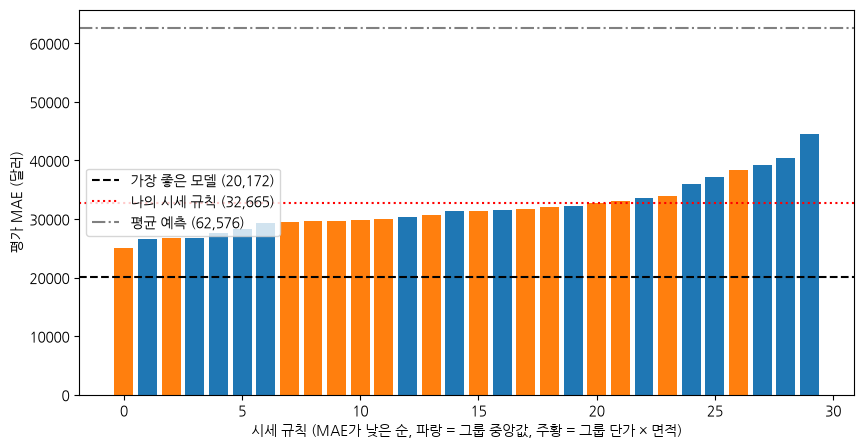

In [61]:
# [제공] 모델과 나의 시세 규칙의 위치
_log = pd.DataFrame(experiment_log)
_models = _log[_log["학습 MAE"].notna()]
_best = _models.sort_values("평가 MAE", kind="stable").iloc[0]
best_mae = float(_best["평가 MAE"])
my_mae = float(m_rule["MAE"])

print(f"가장 좋은 모델 [{_best['실험']}] 평가 MAE {best_mae:,.0f}")
print(f"  MAE로 이기는 시세 규칙: {(rules['평가 MAE'] > best_mae).sum()}개 / {len(rules)}개")
print(f"나의 시세 규칙 [{my_rule_text}] 평가 MAE {my_mae:,.0f}")
print(f"  30개 중 나보다 MAE가 낮은 시세 규칙: {(rules['평가 MAE'] < my_mae).sum()}개")
print()
print("정보 수 × 계산법별 MAE 중앙값")
print(rules.pivot_table(index="정보 수", columns="계산법", values="평가 MAE", aggfunc="median").round(0))

fig, ax = plt.subplots(figsize=(10, 5))
colors = rules["계산법"].map({"(가) 그룹 중앙값": "tab:blue", "(나) 그룹 단가 × 면적": "tab:orange"})
ax.bar(range(len(rules)), rules["평가 MAE"], color=colors)
ax.axhline(best_mae, color="black", linestyle="--", label=f"가장 좋은 모델 ({best_mae:,.0f})")
ax.axhline(my_mae, color="red", linestyle=":", label=f"나의 시세 규칙 ({my_mae:,.0f})")
ax.axhline(m_mean["MAE"], color="gray", linestyle="-.", label=f"평균 예측 ({m_mean['MAE']:,.0f})")
ax.set_xlabel("시세 규칙 (MAE가 낮은 순, 파랑 = 그룹 중앙값, 주황 = 그룹 단가 × 면적)")
ax.set_ylabel("평가 MAE (달러)")
ax.legend(loc="center left")
plt.show()

## 5-7. 결과를 본 뒤

> **[판단]** 예상 ①, ②는 맞았나요? 가장 크게 빗나간 것은 무엇이고, 왜 빗나갔다고 생각하나요?
>
> 나의 답: 예상 ①은 방향은 맞았지만 개수가 빗나갔고(25~28개 예상, 결과 30개 전부), 예상 ②는 빗나갔다(품질 + 동네, (나) 예상, 1위는 품질 + 면적 구간, (나)). 가장 크게 빗나간 것은 ②다. 동네 정보의 효과를 과대평가했고, 품질 + 동네는 그룹이 잘게 나뉘어 단가가 불안정했을 것으로 보인다(108개 중 50개가 5채 이하, 작은 그룹의 집은 MAE 34,788달러로 큰 그룹 28,606달러보다 큼). 다만 이것만으로 1위와의 차이를 다 설명하지는 못한다.

In [63]:
key = train_df["Neighborhood"].astype(str) + " | " + train_df["OverallQual"].astype(str)
sizes = key.value_counts()
print("그룹 수:", len(sizes))
print(sizes.describe())
print("5채 이하 그룹:", (sizes <= 5).sum(), "개")

# 평가용 집 중 학습용에 없는 조합(빈 그룹)이 몇 채인지
test_key = test_df["Neighborhood"].astype(str) + " | " + test_df["OverallQual"].astype(str)
print("학습용에 없는 조합의 평가용 집:", (~test_key.isin(sizes.index)).sum(), "채")

그룹 수: 108
count    108.000000
mean      10.814815
std       13.703910
min        1.000000
25%        2.000000
50%        7.000000
75%       14.000000
max       89.000000
Name: count, dtype: float64
5채 이하 그룹: 50 개
학습용에 없는 조합의 평가용 집: 6 채


In [64]:
key_tr = train_df["Neighborhood"].astype(str) + " | " + train_df["OverallQual"].astype(str)
key_te = test_df["Neighborhood"].astype(str) + " | " + test_df["OverallQual"].astype(str)
size_of = key_te.map(key_tr.value_counts()).fillna(0)

unit = (train_df["SalePrice"] / train_df["GrLivArea"]).groupby(key_tr).median()
pred = key_te.map(unit).fillna((train_df["SalePrice"] / train_df["GrLivArea"]).median()) * test_df["GrLivArea"]
err = (test_df["SalePrice"] - pred).abs()

small = size_of <= 5
print("5채 이하 그룹 집:", small.sum(), "채, MAE", round(err[small].mean()))
print("6채 이상 그룹 집:", (~small).sum(), "채, MAE", round(err[~small].mean()))

5채 이하 그룹 집: 46 채, MAE 34788
6채 이상 그룹 집: 246 채, MAE 28606


> **[판단]** 정보를 1개 쓴 규칙과 2개 쓴 규칙, 계산법 (가)와 (나) 중 어느 쪽의 MAE가 대체로 낮은가요? 계산법 (나)가 유리하거나 불리한 경우는 어떤 정보를 쓸 때인지도 표에서 찾아 보세요.
>
> 나의 답: 정보를 2개 쓴 규칙이 1개 쓴 규칙보다 MAE가 낮다(MAE 중앙값 (가) 30,329 vs 39,265달러, (나) 29,749 vs 32,983달러). 계산법은 (나)가 대체로 낮고, 1개 정보에서 차이가 크다(약 6,300달러, 2개 정보는 약 600달러). 표에서 보면 (나)는 면적 구간을 쓰는 조합(품질 + 면적 구간 25,031 vs 26,569달러, 동네 + 면적 구간 26,712 vs 26,821달러)에서 유리했고, 면적 구간 없이 2개 정보를 쓰는 조합(동네 + 품질 등급 27,599 vs 29,580달러)에서는 (가)가 더 낮았다.

> **[판단]** 가장 좋은 시세 규칙과 가장 좋은 모델의 MAE 차이는 얼마인가요? 이 차이와, 시세 규칙은 누구나 이해하고 바로 쓸 수 있다는 점을 함께 놓고 보면 기획팀에 무엇을 권하겠습니까?
>
> 나의 답: 가장 좋은 규칙(품질 등급 + 면적 구간, (나), 25,031달러)과 가장 좋은 모델(20,172달러)의 MAE 차이는 4,859달러(약 19%)다. 모델이 규칙 30개를 모두 이겼으므로 도입을 검토할 만하지만, 규칙은 누구나 이해하고 바로 쓸 수 있으니 기준선으로 함께 두기를 권한다. 모델은 고가·고품질 매물(예측 30만 달러 이상 또는 품질 8 이상)에서 크게 틀렸으므로 그런 매물에는 자동 시세를 쓰지 않도록 한다.

> **[판단]** 나의 시세 규칙은 30개 사이에서 어디쯤인가요? 정보를 하나 더하거나 계산법을 바꾼다면 어떤 규칙을 고르겠습니까? 위 표에서 그 규칙을 찾아 결과를 적어 보세요.
>
> 나의 답: 내 규칙(품질 등급 + (나), MAE 32,665달러)은 30개 중 21위다(나보다 MAE가 낮은 규칙 20개). 정보를 하나 더한다면 품질 등급 + 면적 구간, (나)를 고르겠다. 표에서 MAE가 25,031달러로 1위이고, 내 규칙보다 7,634달러(약 23%) 낮다.

## 5-6. 기획팀 보고 메모

분석 결과를 기획팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **오차를 어떤 지표로 말할 것인가**: MAE와 RMSE 중 하나를 고르고, 의뢰서의 문장("너무 다르면 플랫폼을 믿지 않게 된다")에 근거해 이유를 쓴다. "평균적으로 ±얼마"를 달러로 적는다.
2. **지금 쓰는 방법(내 시세 규칙)과 비교해 얼마나 나은가**
3. **믿어도 되는 집과 믿으면 안 되는 집**: 5-1의 가격대별 오차에 근거해 구분 기준을 제안한다.
4. **주의할 점**: 1-4의 빈 값 처리 결정, 데이터의 한계(Ames 한 도시의 2006~2010년 거래), 아직 확인하지 못한 것

> **[판단]** 기획팀 보고 메모:
>
> 1. 오차 지표와 ±얼마: RMSE로 말씀드립니다. 시세가 실제 거래가와 너무 다르면 플랫폼을 믿지 않게 되므로, 가끔 크게 틀리는 것을 더 무겁게 보는 지표가 맞다고 보았습니다. 이 모델의 시세는 평균적으로 약 ±3만 3천 달러(RMSE 32,698달러) 차이가 납니다.
>
> 2. 시세 규칙과의 비교: 현행 규칙(RMSE 44,289달러)보다 오차가 약 1만 1천 달러(26%) 작습니다.
>
> 3. 믿어도 되는 집 / 믿으면 안 되는 집: 10만~20만 달러대 매물은 평균 오차가 약 1만 4천 달러로 가장 작아 믿어도 됩니다. 예측 가격이 30만 달러 이상이거나 품질 등급이 8 이상인 매물은 오차가 크고 실제가가 시세보다 비싼 경우가 많아 믿으면 안 됩니다.
>
> 4. 주의할 점: 지하실 품질의 빈 칸 37채는 모두 지하실 면적이 0이어서 "없음"으로 처리했습니다. 이 결과는 미국 에임스 한 도시의 2006~2010년 거래 292채로 확인한 것이고, 50만 달러 이상 집은 3채뿐이라 최고가 구간은 아직 확인하지 못했습니다.
>
> 나의 답: 모델 시세 도입을 권하되, 30만 달러 이상이거나 품질 8 이상인 매물은 자동 시세 대신 사람의 확인을 거치도록 제안합니다.

---
# 마무리

## 이 Chapter의 판단 포인트

> **MAE와 RMSE 중 무엇을 보고서에 쓸 것인가? 큰 오차를 얼마나 아프게 볼지는 지표가 아니라 비즈니스가 정한다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "회귀 모델의 오차를 보면 평균 예측과 현행 시세 규칙의 오차를 먼저 찾는다."

> **[판단]** 나의 체크리스트 2번(회귀 지표를 볼 때):
>
> 나의 답: 회귀 지표를 볼 때는 MAE와 RMSE를 함께 보고, 큰 오차를 얼마나 중요하게 볼지에 따라 보고 지표를 고른다. 평균 예측과 중앙값 예측에서 두 지표의 순위가 갈렸고(MAE는 중앙값, RMSE는 평균이 낮음), 3차 다항도 MAE는 내 규칙보다 낮은데 RMSE는 훨씬 높았다.

> **[판단]** 나의 체크리스트 3번(학습용 점수와 평가용 점수를 볼 때):
>
> 나의 답: 학습용 점수만 보지 않고 평가용 점수와 같이 놓고 격차를 본다. 3차 다항은 학습 MAE 11,736달러인데 평가 MAE는 29,235달러로 약 2.5배였고, Ridge를 쓰자 격차가 줄었다. 반대로 다중회귀 5개는 격차가 4% 정도로 작아 과적합이 아니었다. 평가용 점수를 보고 모델이나 규칙을 고르면 평가용 점수가 실제보다 좋아 보이므로, 고르는 기준은 학습용 안에서 정한다.

## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 3에서는 확률을 예측하는 **분류**를 배웁니다.